Q1

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(r"C:\Users\Administrator\Downloads\ride_hailing_dataset.csv")
print(df.head())

  trip_id       city service_type    fare  distance_km payment_method  \
0    T001     Lahore         Uber  984.44         17.2           Cash   
1    T002  Islamabad         Uber  539.46          2.5         Wallet   
2    T003    Karachi       Careem  401.60          8.0           Card   
3    T004     Lahore         Uber  932.56         16.2         Wallet   
4    T005     Lahore     Rickshaw  148.61         19.2           Card   

   trip_rating  gender  
0            3  Female  
1            5  Female  
2            4    Male  
3            3  Female  
4            5  Female  


In [4]:
avg_fare_by_service = (
    df.groupby("service_type")["fare"].mean().sort_values(ascending=False))
print(avg_fare_by_service.round(2))

service_type
InDrive     573.51
Careem      544.98
Rickshaw    486.64
Uber        486.13
Name: fare, dtype: float64


Q2

In [5]:
trips_by_city = df["city"].value_counts()
print(trips_by_city)
print(f"\nCity with the most trips: {trips_by_city.index[0]}"
    f" ({trips_by_city.iloc[0]} trips)")

city
Islamabad     29
Lahore        26
Karachi       23
Rawalpindi    22
Name: count, dtype: int64

City with the most trips: Islamabad (29 trips)


Q3

In [6]:
avg_distance = df["distance_km"].mean()
print(f"Average distance per trip: {avg_distance:.2f} km")

Average distance per trip: 9.61 km


Q4

In [9]:
ratings_by_gender = df.groupby("gender")["trip_rating"].agg(
    count="count", mean="mean", median="median", min="min", max="max", std="std")
print(ratings_by_gender.round(2))

        count  mean  median  min  max   std
gender                                     
Female     51  2.82     3.0    1    5  1.47
Male       49  3.33     4.0    1    5  1.46


Q5

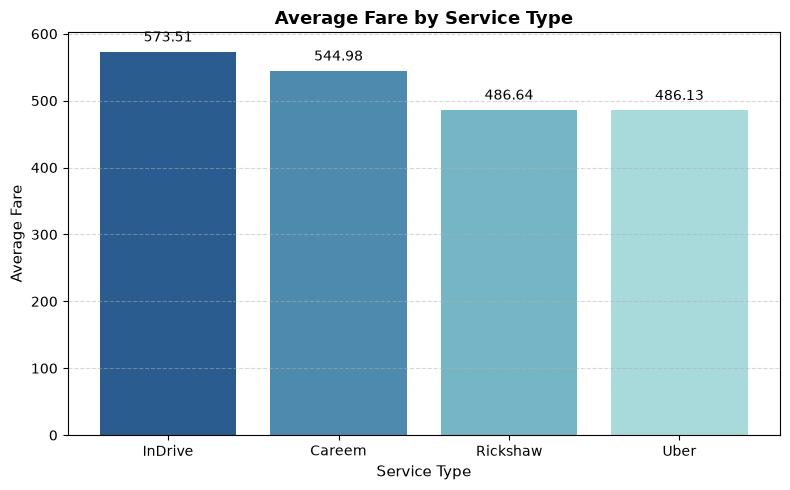

In [10]:
avg_fare = df.groupby("service_type")["fare"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
bars = plt.bar(
    avg_fare.index,
    avg_fare.values,
    color=["#2b5c8f", "#4e89ae", "#76b5c5", "#a8dadc"],)
plt.title("Average Fare by Service Type", fontsize=13, fontweight="bold")
plt.xlabel("Service Type", fontsize=11)
plt.ylabel("Average Fare", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2,
      height + 10,
      f"{height:.2f}",
      ha="center",
      va="bottom",
      fontsize=10,
  )

plt.tight_layout()
plt.show()